# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Mettakusuma
- **Email:** mettakusumawu@gmail.com
- **ID Dicoding:** mettakusuma

## Menentukan Pertanyaan Bisnis

**1. Berapa total jumlah penyewaan sepeda pada masing-masing musim selama periode tahun 2011-2012, dan pada musim apakah tim operasional harus menjadwalkan pemeliharaan armada masif agar kerugian pendapatan dapat diminimalisir?

**Penjelasan SMART:**
- **Specific:** Fokus membandingkan performa penyewaan di 4 musim berbeda untuk mencari titik terendah.
- **Measurable:** Dihitung menggunakan metrik "total jumlah penyewaan" (`cnt`).
- **Action-Oriented:** Hasilnya langsung menentukan kapan "jadwal pemeliharaan armada (maintenance)" harus dieksekusi.
- **Relevant:** Sangat relevan dengan masalah operasional bisnis, yaitu menjaga kondisi sepeda tanpa mengganggu pendapatan saat *peak season*.
- **Time-bound:** Dibatasi "selama periode tahun 2011-2012" sesuai dataset.

**2. Berapa rata-rata penyewaan sepeda per jam pada hari kerja (working day) dibandingkan weekend sepanjang tahun 2011-2012, dan di waktu kapankah perusahaan harus memprioritaskan alokasi armada di stasiun perkantoran vs area rekreasi?

**Penjelsan SMART:**
- **Specific:** Membandingkan pola jam sibuk antara dua tipe hari (hari kerja dan libur).
- **Measurable:** Dihitung menggunakan angka konkrit yaitu "rata-rata penyewaan per jam".
- **Action-Oriented:** Stakeholder jadi tahu kapan dan di mana harus melakukan "prioritas alokasi armada" (perkantoran atau rekreasi).
- **Relevant:** Berkaitan langsung dengan efisiensi distribusi unit sepeda di lapangan (bisnis logistik).
- **Time-bound:** Dibatasi "sepanjang tahun 2011-2012".

## Import Semua Packages/Library yang Digunakan

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Data Wrangling

### Gathering Data

#### Load df dari dataset bike sharing

In [7]:
df_hari = pd.read_csv("data/day.csv")
df_jam = pd.read_csv("data/hour.csv")

display(df_hari.head())

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


**Insight:** (Opsional)
- Dataset `day.csv` dan `hour.csv` berhasil dimuat dengan baik.
- Dataset ini memuat rekam jejak penyewaan beserta kondisi cuaca dan waktu yang siap untuk dianalisis.

### Assessing Data

#### menidentifikasi value yang ilang dan tipe data

In [8]:
print(df_jam.info())
print("\nMissing Values:\n", df_jam.isna().sum())
print("\nDuplicate Data:", df_jam.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB
None

Missing Values:
 instant       0
dteday    

**Steps to Take:**
- Mengubah tipe data kolom `dteday` menjadi `datetime`.
- Memetakan nilai numerik pada kolom `season` dan `workingday` menjadi kategori string deskriftif.

**Insight:** (Opsional)
- Tidak terdapat *missing value* maupun duplikasi data pada dataset, sehingga data relatif bersih dan hanya perlu penyesuaian tipe data.

### Cleaning Data

memperbaiki tipe data dan mengelompokan kategori

In [9]:
df_hari['dteday'] = pd.to_datetime(df_hari['dteday'])
df_jam['dteday'] = pd.to_datetime(df_jam['dteday'])

mapingmusim = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
df_jam['season_label'] = df_jam['season'].map(mapingmusim)
df_jam['workingday_label'] = df_jam['workingday'].map({1: 'Working Day', 0: 'Weekend'})

**Insight:** (Opsional)
- Kolom tanggal telah diformat dengan benar menjadi `datetime`.
- Kolom label (`season_label` dan `workingday_label`) siap digunakan untuk proses eksplorasi (EDA).

#### menerapkan clustering waktu dalam sehari

In [10]:
def get_time_of_day(hour):
    if 5 <= hour < 12:
        return 'Pagi'
    elif 12 <= hour < 17:
        return 'Siang'
    elif 17 <= hour < 21:
        return 'Sore'
    else:
        return 'Malam'

df_jam['katewaktu'] = df_jam['hr'].apply(get_time_of_day)

time_order = ['Pagi', 'Siang', 'Sore', 'Malam']
df_jam['katewaktu'] = pd.Categorical(df_jam['katewaktu'], categories=time_order, ordered=True)

df_jam.to_csv("dashboard/main_data.csv", index=False)

**Insight:** (Opsional)
- Penggunaan teknik Binning (Clustering manual) berhasil mengelompokkan 24 jam menjadi 4 kelompok utama (Pagi, Siang, Sore, Malam) untuk mempermudah deteksi perilaku komuter.

## Exploratory Data Analysis (EDA)

### 1. EDA Univariat (Distribusi Data)

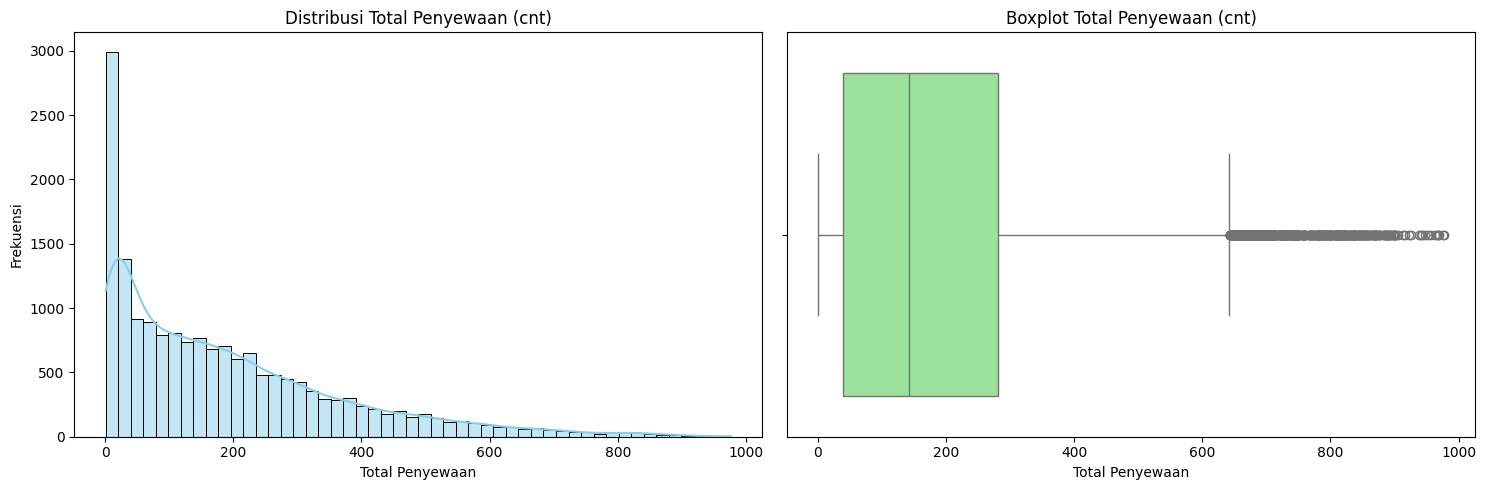

In [11]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))

sns.histplot(df_jam['cnt'], bins=50, kde=True, ax=ax[0], color='skyblue')
ax[0].set_title('Distribusi Total Penyewaan (cnt)')
ax[0].set_xlabel('Total Penyewaan')
ax[0].set_ylabel('Frekuensi')

sns.boxplot(x=df_jam['cnt'], ax=ax[1], color='lightgreen')
ax[1].set_title('Boxplot Total Penyewaan (cnt)')
ax[1].set_xlabel('Total Penyewaan')

plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Dari histogram, distribusi penyewaan sepeda cenderung condong ke kanan. Artinya, sebagian besar waktu dalam sehari memiliki jumlah penyewaan yang relatif rendah (0-200 penyewaan per jam).
- Dari boxplot, terlihat cukup banyak *outlier* atas (titik-titik di luar garis batas kanan). Outlier ini sebenarnya adalah hal yang wajar dan valid, karena merepresentasikan jam-jam sibuk (*peak hours*) di mana jumlah penyewaan melonjak drastis dibandingkan jam biasa.

### 2. EDA Multivariat (Korelasi Antar Variabel Numerik)

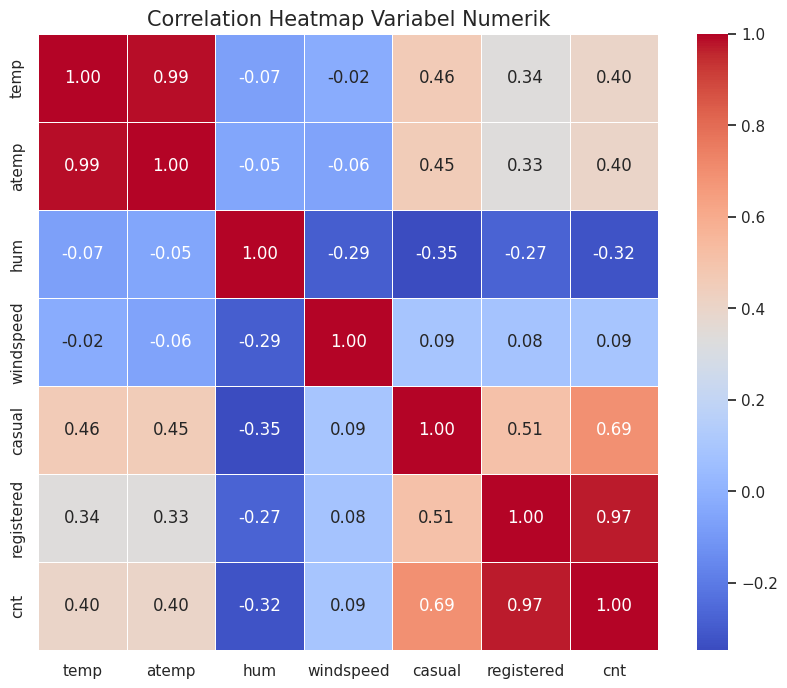

In [16]:
numeric_cols = ['temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']
corr_matrix = df_jam[numeric_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap Variabel Numerik', fontsize=15)
plt.show()

**Insight:** (Opsional)
- Variabel suhu (`temp` dan `atemp`) memiliki korelasi positif sedang (sekitar 0.40) terhadap total penyewaan (`cnt`). Hal ini menunjukkan bahwa cuaca yang lebih hangat cenderung meningkatkan minat orang menyewa sepeda.
- Variabel kelembaban (`hum`) memiliki korelasi negatif (-0.32) terhadap `cnt`. Artinya, ketika tingkat kelembaban terlalu tinggi (misalnya saat hujan atau mendung tebal), jumlah penyewaan cenderung menurun.
- Variabel kecepatan angin (`windspeed`) memiliki korelasi yang sangat kecil, sehingga tidak terlalu berdampak signifikan pada jumlah penyewaan.
- Temuan ini sangat mendukung analisis kita pada Pertanyaan Bisnis 1, di mana penyewaan terendah terjadi di musim dengan suhu ekstrem/rendah seperti Musim Semi (Spring).

## Analisis Lanjutan (Opsional)

### Explore tren musim dan jam kerja

In [12]:
season_rentals = df_jam.groupby('season_label')['cnt'].sum().reset_index()

time_rentals = df_jam.groupby(['katewaktu', 'workingday_label'], observed=False)['cnt'].mean().reset_index()

**Insight:** (Opsional)
- Data berhasil diagregasi (groupby) untuk menjawab pertanyaan yang diajukan dengan SMART.

## Visualization & Explanatory Analysis

### Pertanyaan 1: total penyewaan berdasarkan musim

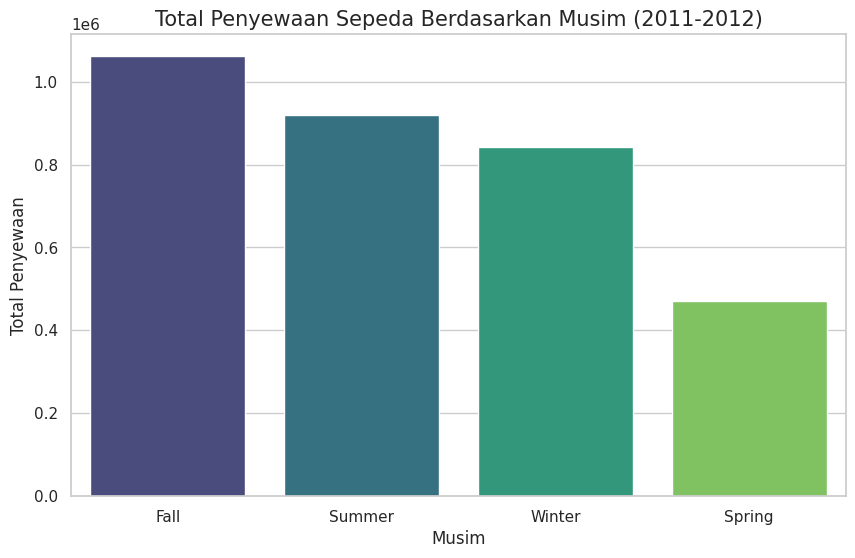

In [13]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))
sns.barplot(
    x='season_label',
    y='cnt',
    hue='season_label',
    data=season_rentals.sort_values(by='cnt', ascending=False),
    palette='viridis',
    legend=False
)
plt.title('Total Penyewaan Sepeda Berdasarkan Musim (2011-2012)', fontsize=15)
plt.xlabel('Musim', fontsize=12)
plt.ylabel('Total Penyewaan', fontsize=12)
plt.show()

### Pertanyaan 2: Rata Rata penyewaan sepeda (harikerja vs hari libur)

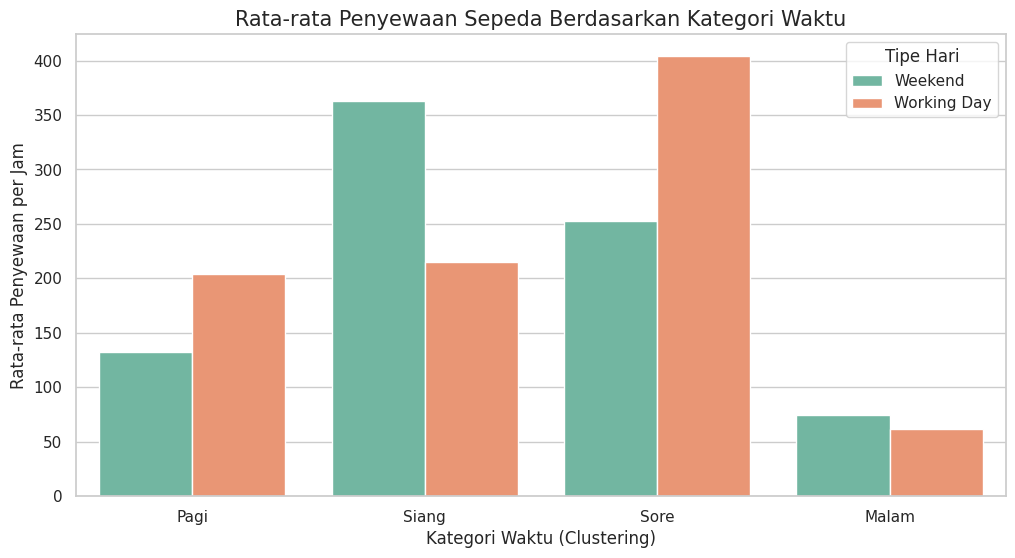

In [14]:
plt.figure(figsize=(12, 6))
sns.barplot(
    x='katewaktu',
    y='cnt',
    hue='workingday_label',
    data=time_rentals,
    palette='Set2'
)
plt.title('Rata-rata Penyewaan Sepeda Berdasarkan Kategori Waktu', fontsize=15)
plt.xlabel('Kategori Waktu (Clustering)', fontsize=12)
plt.ylabel('Rata-rata Penyewaan per Jam', fontsize=12)
plt.legend(title='Tipe Hari')
plt.show()

**Insight:** (Opsional)
- Terdapat perbedaan grafik yang signifikan pada distribusi peminjaman di hari kerja (Bimodal/dua puncak) dibandingkan di hari libur (Unimodal/satu puncak).

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:**
Berdasarkan hasil analisis data tahun 2011-2012, Musim Gugur (*Fall*) mencetak rekor penyewaan tertinggi. Sebaliknya, Musim Semi (*Spring*) mencatat penyewaan paling rendah secara drastis. Berdasarkan hasil tren analisis sehingga secara keseluruhan, tren penyewaan sepeda sejalan dengan tingkat kenyamanan cuaca. Penyewaan meningkat tajam setelah musim semi (*Spring*), mencapai puncak tertinggi pada musim gugur(*Summer*), dan kembali merosot saat memasuki musim dingin(*Winter*) akibat suhu ekstrem.
- **Conclusion pertanyaan 2:** Pada hari kerja (*Working Day*), rata-rata penyewaan memuncak tajam di waktu *Sore* dan *Pagi*. Berbanding terbalik dengan akhir pekan (*Weekend*), di mana peminjaman terpusat pada *Siang* hari. Berdasarkan hasil tren analisis terlihat pola perilaku pengguna yang berlawanan. Hari kerja menunjukkan pola komuter (dua puncak) untuk berangkat dan pulang kerja. Sedangkan akhir pekan menunjukkan pola rekreasi (satu puncak) untuk bersantai.

**Rekomendasi Action Item:**
- **Pemeliharaan (Maintenance):** Perusahaan disarankan menjadwalkan program *maintenance* massal pada Musim Semi (*Spring*). Karena *demand* pasar sedang sangat sepi, penarikan sebagian armada tidak akan mengganggu pelayanan.
- **Distribusi Armada Logistik:** Terapkan alokasi dinamis. Di hari kerja, perbanyak sepeda di area perumahan saat pagi, dan area perkantoran saat sore. Pada akhir pekan, alihkan fokus suplai ke taman kota atau area rekreasi pada jam siang.